# 04 – Đánh giá mô hình 3 mức (Evaluation)

- **Học phần:** Ứng dụng AI trong công nghiệp
- **Dataset:** SECOM (1567 mẫu, 590 đặc trưng, nhãn Pass/Fail, có timestamp)
- **Mục tiêu của notebook:** Đánh giá mô hình cuối trên test ở ba mức model, system, industrial và kết luận mức chấp nhận.
- **Bước lifecycle:** 6. Evaluation
- **Bài lab của thầy tham chiếu:** Lab 03 và Lab 06
- **Input (đọc từ):** `data/secom/` qua `load_secom`; `artifacts/model_lr.joblib`, `model_rf.joblib`, `model_final.joblib`, `decision_config.json` (từ notebook 03). Split không đọc từ file: gọi lại `get_split` và kiểm tra 314 dòng test, 21 Fail.
- **Output (lưu vào):** `artifacts/results/test_model_metrics.csv`, `test_predictions.csv`, `test_system_metrics.csv` (gồm cả số đo mức industrial), `test_robustness.csv`; hình `figures/fig_04_*.png`

**Nguyên tắc của notebook này:** test là tập giữ riêng, chỉ được **dùng một lần để đánh giá**. Không `.fit()`, không tuning, không đổi ngưỡng. Score test được tính một lần cho mỗi model rồi dùng lại. Logistic Regression và Random Forest là đối chứng đã xác định trước ở notebook 03; **không chọn lại mô hình có điểm test cao nhất**.

**Nhãn từng mục:** *Kế thừa từ lab*, *Điều chỉnh từ lab*, *Nhóm bổ sung*.

## 0. Import và đường dẫn

*Nhãn: Kế thừa từ lab (Lab 03, cell 6); điều chỉnh: dùng `secom_utils` và `Path`.*

In [1]:
import json
import os
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.metrics import ConfusionMatrixDisplay, precision_recall_curve

from secom_utils import (
    SEED, TEST_SIZE,
    ARTIFACT_DIR, RESULTS_DIR, FIGURES_DIR,
    load_secom, get_split, load_artifact,
    evaluate_classifier,
)
from secom_preprocessing import MissingRateSelector  # cần import được để nạp model đã lưu

pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 50)

FIGURES_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("SEED =", SEED, "| TEST_SIZE =", TEST_SIZE)

SEED = 42 | TEST_SIZE = 0.2


## 1. Nạp model, ngưỡng và test set

*Nhãn: Điều chỉnh từ lab (Lab 03, mục 9: dựng lại tập test); nhóm bổ sung: kiểm tra split và không chạm vào model.*

Gọi lại `get_split`, dựng `X_test_raw`, `y_test`, `timestamp_test` cùng thứ tự; nạp ba model và `decision_config.json`. Model nhận thẳng **590 cột thô** nên không transform bằng pipeline notebook 02. Ô này tính score test **một lần** cho mỗi model; kết quả hiệu năng chỉ in ra sau khi mục 2 đã nêu tiêu chí.

In [2]:
X, y, timestamp = load_secom()

train_idx, test_idx = get_split(y, test_size=TEST_SIZE, seed=SEED)
X_train_raw = X.iloc[train_idx]
y_train = y.iloc[train_idx]
X_test_raw = X.iloc[test_idx]
y_test = y.iloc[test_idx]
timestamp_test = timestamp.iloc[test_idx]

# Kiểm tra split đã chốt: lệch thì báo lỗi, không âm thầm đi tiếp
assert (len(train_idx), len(test_idx)) == (1253, 314), "Số dòng train/test lệch 1253/314"
assert (int(y_train.sum()), int(y_test.sum())) == (83, 21), "Số Fail train/test lệch 83/21"

n_test = len(y_test)
n_test_fail = int(y_test.sum())
n_test_pass = n_test - n_test_fail
print("X_test_raw:", X_test_raw.shape, "| Fail:", n_test_fail, "| Pass:", n_test_pass)
print("Split đúng: train/test = 1253 / 314, Fail train/test = 83 / 21")

X_test_raw: (314, 590) | Fail: 21 | Pass: 293
Split đúng: train/test = 1253 / 314, Fail train/test = 83 / 21


In [3]:
# Nạp cấu hình và model đã chốt ở notebook 03; không fit, không đổi gì
with open(ARTIFACT_DIR / "decision_config.json", encoding="utf-8") as config_file:
    config = json.load(config_file)

model_lr = load_artifact("model_lr.joblib")
model_rf = load_artifact("model_rf.joblib")
model_final = load_artifact("model_final.joblib")

final_model_name = config["model"]
threshold = float(config["threshold"])
selected_original_columns = config["selected_original_columns"]
models_by_name = {"logistic_regression": model_lr, "random_forest": model_rf}

print("Model cuối:", final_model_name)
print("Ngưỡng đã chốt ở notebook 03:", threshold)
print("class_weight:", config["class_weight"], "| k:", config["k"])
print("Số cột thô model nhận:", model_final.named_steps["preprocess"].named_steps["missing_rate"].n_features_in_)

Model cuối: random_forest
Ngưỡng đã chốt ở notebook 03: 0.14
class_weight: balanced | k: 40
Số cột thô model nhận: 590


In [4]:
# Score Fail trên test: tính một lần mỗi model rồi dùng lại về sau
fail_column = list(model_final.classes_).index(1)

score_lr = model_lr.predict_proba(X_test_raw)[:, fail_column]
score_rf = model_rf.predict_proba(X_test_raw)[:, fail_column]
score_final = model_final.predict_proba(X_test_raw)[:, fail_column]

# model_final phải trùng đúng model được nêu trong cấu hình
assert np.allclose(score_final, {"logistic_regression": score_lr, "random_forest": score_rf}[final_model_name]), "model_final không khớp decision_config.json"
print("Đã tính score test cho LR, RF và model cuối:", score_final.shape)

Đã tính score test cho LR, RF và model cuối: (314,)


Đọc ngưỡng Logistic Regression do notebook 03 (mục 8.1) chọn từ OOF của train. Không tính lại, không dùng test để chọn.

In [5]:
# Ngưỡng Logistic Regression do notebook 03 (mục 8.1) chọn từ OOF của train; ở đây chỉ đọc, không tính lại
assert "threshold_lr" in config and "threshold_rule" in config, "decision_config.json thiếu threshold_lr / threshold_rule: chạy lại notebook 03"
threshold_lr = float(config["threshold_lr"])
print("Ngưỡng LR đọc từ decision_config.json:", round(threshold_lr, 4))
print("Quy tắc:", config["threshold_rule"])
print("Ngưỡng này được thêm sau lần xem test đầu tiên, chọn chỉ từ OOF-train; model cuối vẫn là", final_model_name, "@", threshold)
assert final_model_name == "random_forest" and threshold == 0.14, "Mô hình cuối hoặc ngưỡng RF đã đổi"

Ngưỡng LR đọc từ decision_config.json: 0.8361
Quy tắc: F1 Fail cao nhất trên OOF-train; bằng F1 thì chọn ngưỡng cao hơn
Ngưỡng này được thêm sau lần xem test đầu tiên, chọn chỉ từ OOF-train; model cuối vẫn là random_forest @ 0.14


### Nhận xét

- **Phát hiện:** split dựng lại đúng 314 dòng test (21 Fail, 293 Pass). Model cuối là Random Forest với ngưỡng 0,14, đọc từ `decision_config.json`; model nhận 590 cột thô và `model_final` cho cùng score với `model_rf`.
- **Ảnh hưởng:** score test đã tính một lần cho Logistic Regression, Random Forest và model cuối, chưa in chỉ số nào; không fit và không đổi ngưỡng.
- **Kết luận:** tiêu chí chấp nhận được nêu ở mục 2, trước mọi kết quả hiệu năng.

## 2. Tiêu chí chấp nhận

*Nhãn: Nhóm bổ sung (slide 03: đặt tiêu chí trước khi đánh giá cuối).*

Các tiêu chí dưới đây do nhóm tự đặt, **chốt trước khi xem bất kỳ kết quả test nào** trong notebook này. Không lưu thành file; nếu đổi phải đổi ở đây **trước** khi chạy test và ghi rõ.

| Mức | Tiêu chí | Cách kết luận |
|---|---|---|
| **Kỹ thuật** | Average Precision của mô hình cuối trên test **lớn hơn tỷ lệ Fail của train** (mốc ngây thơ); Balanced Accuracy **lớn hơn 0,5** | Đạt hoặc chưa đạt: có tín hiệu hơn mốc ngây thơ |
| **Vận hành (system)** | Báo FPR, tỷ lệ cảnh báo, latency toàn pipeline cho một quan sát, thời gian train, kích thước model và độ giảm chỉ số khi thêm nhiễu hay che thêm dữ liệu. **Chưa đặt mục tiêu số** vì SECOM không có năng lực kiểm tra, yêu cầu thời gian thực hay mức chịu cảnh báo giả của nhà máy | Chỉ báo cáo số đo; ghi "chưa đủ dữ liệu" |
| **Công nghiệp** | Báo TP, FN, FP và tải kiểm tra; mô tả luồng kỹ sư xác nhận trước khi hành động. Chưa có chi phí hay ROI | Chỉ báo cáo; ghi "chưa đủ dữ liệu" cho lợi ích kinh tế |

**Quy tắc verdict cho prototype:**

- **Accept**: chỉ khi đạt mọi tiêu chí định lượng đã đặt, mọi mức đều đủ dữ liệu để kết luận và có luồng human-in-the-loop được mô tả.
- **Improve**: có tín hiệu kỹ thuật nhưng còn thiếu tiêu chí vận hành/công nghiệp hoặc độ ổn định.
- **Redesign**: không đạt tiêu chí kỹ thuật cơ bản.
- Nếu tải cảnh báo hay chỉ số nào không như mong muốn thì ghi đúng như đo được, **không tăng ngưỡng hay đổi model để ép đạt**.
- Luôn ghi riêng câu: "chưa đủ bằng chứng chấp nhận triển khai nhà máy".

## 3. Model-level

*Nhãn: Kế thừa từ lab (Lab 03, cell 31, 37, 39: chỉ số, bảng so sánh, confusion matrix; bài làm Lab 06, cell 26: PR curve); bổ sung ROC-AUC và Average Precision. Không chép Lab 03 cell 45 (quét ngưỡng trên test).*

- Báo Accuracy (tham khảo), Precision / Recall / F1 của Fail, ROC-AUC, Average Precision (`average_precision_score`, không phải diện tích hình thang của đường PR), Balanced Accuracy, BER và TP / FP / FN / TN.
- Ngưỡng: **0,5** và **ngưỡng đã chốt ở notebook 03**. Ngưỡng chốt chỉ có cho model cuối; Logistic Regression hay Random Forest không phải model cuối thì chỉ có ngưỡng 0,5. Không thử ngưỡng mới trên test.
- Metric không xác định được ghi NaN; ở đây test có cả Pass lẫn Fail nên mọi metric đều xác định.

In [6]:
final_label = "Mô hình cuối (" + final_model_name + ") @ ngưỡng chốt " + str(round(threshold, 4))

policy_list = [
    ("Logistic Regression @ 0,5", score_lr, 0.5),
    ("Random Forest @ 0,5", score_rf, 0.5),
    (final_label, score_final, threshold),
]

metric_rows = []
for policy_name, policy_score, policy_threshold in policy_list:
    row = evaluate_classifier(y_test.to_numpy(), policy_score, policy_threshold)
    row["Mô hình"] = policy_name
    metric_rows.append(row)

metric_columns = ["Mô hình", "threshold", "accuracy", "precision", "recall", "f1",
                  "roc_auc", "average_precision", "balanced_accuracy", "ber", "tp", "fp", "fn", "tn"]
test_model_metrics = pd.DataFrame(metric_rows)[metric_columns]
display(test_model_metrics.round(4))

test_model_metrics.to_csv(RESULTS_DIR / "test_model_metrics.csv", index=False)
print("Đã lưu: test_model_metrics.csv")

,Mô hình,threshold,accuracy,precision,recall,f1,roc_auc,average_precision,balanced_accuracy,ber,tp,fp,fn,tn
0,"Logistic Regression @ 0,5",0.50,0.7325,0.1461,0.619,0.2364,0.7265,0.1760,0.6798,0.3202,13,76,8,217
1,"Random Forest @ 0,5",0.50,0.9331,0.0000,0.000,0.0000,0.7487,0.2102,0.5000,0.5000,0,0,21,293
2,Mô hình cuối (random_forest) @ ngưỡng chốt 0.14,0.14,0.8758,0.2353,0.381,0.2909,0.7487,0.2102,0.6461,0.3539,8,26,13,267


Đã lưu: test_model_metrics.csv


In [7]:
# Số đếm tuyệt đối của model cuối (mẫu số lấy từ dữ liệu)
final_metrics = evaluate_classifier(y_test.to_numpy(), score_final, threshold)

print(f"Model cuối phát hiện {final_metrics['tp']}/{n_test_fail} Fail (Recall = {final_metrics['recall']:.4f})")
print(f"Bỏ sót {final_metrics['fn']}/{n_test_fail} Fail")
print(f"{final_metrics['fp']}/{n_test_pass} Pass bị cảnh báo nhầm (FPR = {final_metrics['fpr']:.4f})")
print(f"Mỗi ca Fail đúng/sai làm Recall đổi {100 / n_test_fail:.2f} điểm phần trăm")
print("Không có khoảng tin cậy: chỉ báo số đếm và giới hạn này (test chỉ có", n_test_fail, "Fail).")

# So với CV ở notebook 03 (chỉ để đối chiếu, không dùng để chọn lại gì)
cv_comparison = pd.read_csv(RESULTS_DIR / "cv_model_comparison.csv")
cv_rf = cv_comparison[cv_comparison["Mô hình"].str.startswith("Random Forest")].iloc[0]
print(f"AP trong CV ở notebook 03 (Random Forest): {cv_rf['AP_mean']:.4f} ± {cv_rf['AP_std']:.4f}")
print(f"AP của model cuối trên test: {final_metrics['average_precision']:.4f}")

Model cuối phát hiện 8/21 Fail (Recall = 0.3810)
Bỏ sót 13/21 Fail
26/293 Pass bị cảnh báo nhầm (FPR = 0.0887)
Mỗi ca Fail đúng/sai làm Recall đổi 4.76 điểm phần trăm
Không có khoảng tin cậy: chỉ báo số đếm và giới hạn này (test chỉ có 21 Fail).
AP trong CV ở notebook 03 (Random Forest): 0.2038 ± 0.0701
AP của model cuối trên test: 0.2102


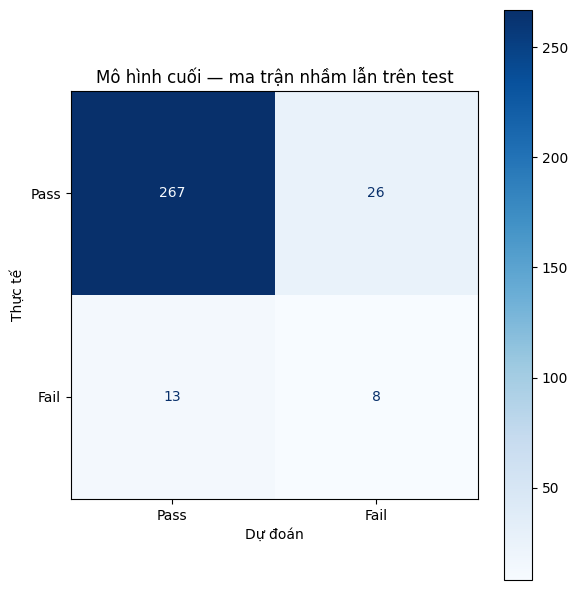

In [8]:
fig, ax = plt.subplots(figsize=(6, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test, (score_final >= threshold).astype(int), labels=[0, 1],
    display_labels=["Pass", "Fail"], cmap="Blues", ax=ax,
)
ax.set_title("Mô hình cuối — ma trận nhầm lẫn trên test")
ax.set_xlabel("Dự đoán")
ax.set_ylabel("Thực tế")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_04_confusion_matrix.png", dpi=150)
plt.show()

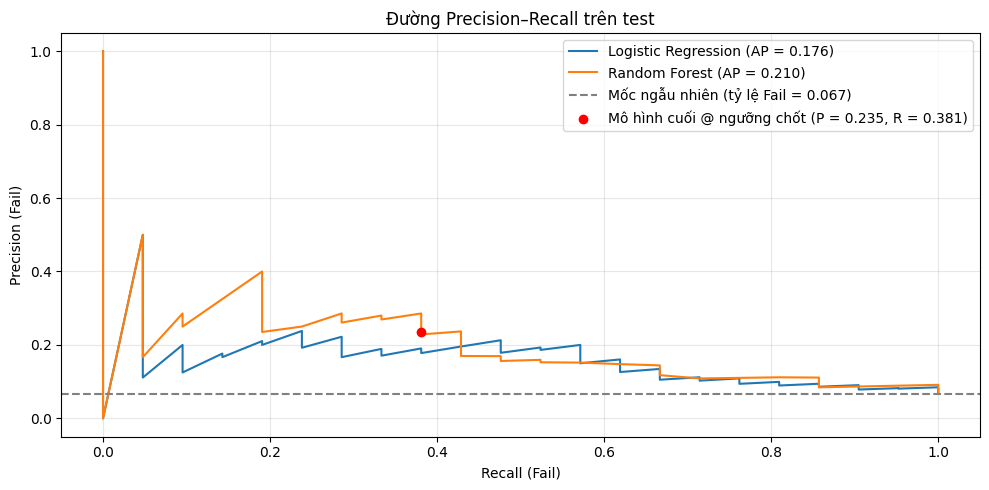

In [9]:
# Chỉ vẽ PR curve (ROC-AUC giữ ở dạng số trong bảng, không vẽ ROC)
plt.figure(figsize=(10, 5))
for curve_name, curve_score in [("Logistic Regression", score_lr), ("Random Forest", score_rf)]:
    precision_values, recall_values, _ = precision_recall_curve(y_test, curve_score)
    ap_value = evaluate_classifier(y_test.to_numpy(), curve_score, 0.5)["average_precision"]
    plt.plot(recall_values, precision_values, label=f"{curve_name} (AP = {ap_value:.3f})")

plt.axhline(n_test_fail / n_test, color="gray", linestyle="--", label=f"Mốc ngẫu nhiên (tỷ lệ Fail = {n_test_fail / n_test:.3f})")
plt.scatter([final_metrics["recall"]], [final_metrics["precision"]], color="red", zorder=5,
            label=f"Mô hình cuối @ ngưỡng chốt (P = {final_metrics['precision']:.3f}, R = {final_metrics['recall']:.3f})")
plt.xlabel("Recall (Fail)")
plt.ylabel("Precision (Fail)")
plt.title("Đường Precision–Recall trên test")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_04_pr_curve.png", dpi=150)
plt.show()

### Nhận xét

- **Phát hiện:** model cuối (Random Forest, ngưỡng 0,14) phát hiện **8/21 Fail** (Recall 0,381), bỏ sót 13/21, và cảnh báo nhầm **26/293 Pass** (FPR 0,089). Precision 0,235, F1 0,291, AP 0,210, ROC-AUC 0,749, Balanced Accuracy 0,646, BER 0,354. Ở ngưỡng 0,5, Random Forest không gắn cờ quan sát nào (Recall 0) nhưng AP và ROC-AUC giữ nguyên vì hai chỉ số này không phụ thuộc ngưỡng. Logistic Regression @ 0,5 phát hiện 13/21 Fail nhưng cảnh báo nhầm 76/293 Pass (Precision 0,146, BER 0,320, AP 0,176). Để so sánh: luôn đoán Pass sẽ đạt Accuracy 293/314 = 0,933 nhưng không phát hiện Fail nào; mốc AP ngẫu nhiên là tỷ lệ Fail của test (0,067).
- **Ảnh hưởng:** AP test 0,210 gần AP trong CV ở notebook 03 (0,204 ± 0,070), nên không thấy dấu hiệu AP bị lạc quan. F1 ở ngưỡng chốt trên test (0,291) cao hơn trên OOF (0,230), nhưng test chỉ có 21 Fail: mỗi ca Fail đúng hay sai làm Recall đổi 4,76 điểm phần trăm, nên chênh lệch cỡ này nằm trong dao động. Logistic Regression @ 0,5 có BER thấp hơn model cuối (0,320 so với 0,354) nhưng gắn cờ 89 quan sát, so với 34 của model cuối. Đây là đối chứng xác định trước, chênh nhau vài ca trên 21 Fail, và **không dùng để chọn lại model**.
- **Kết luận:** model cuối có tín hiệu hơn mốc ngây thơ (AP 0,210 so với 0,067; Balanced Accuracy 0,646 > 0,5) nhưng ở mức khiêm tốn: bắt chưa tới 2/5 số Fail, và khoảng 1 trong 4 cảnh báo là đúng. Score có thể chưa hiệu chỉnh (do class weight), nên dashboard sau này nên gọi là risk score.

### 3.1. Logistic Regression ở ngưỡng chọn từ OOF (thêm sau lần xem test đầu tiên)

*Nhãn: Nhóm bổ sung.*

Ngưỡng này được **thêm sau lần xem test đầu tiên** để so sánh Logistic Regression với Random Forest cùng điều kiện (cả hai đều có ngưỡng chọn bằng cùng quy tắc trên OOF của train). Ngưỡng đọc từ `decision_config.json`, **không chọn bằng điểm test** và không dùng test để chỉnh. Chỉ thêm một dòng vào bảng model-level; các dòng cũ giữ nguyên. Logistic Regression **không** thay Random Forest làm model cuối.

In [10]:
lr_label = "Logistic Regression @ ngưỡng OOF " + str(round(threshold_lr, 4))
lr_oof_metrics = evaluate_classifier(y_test.to_numpy(), score_lr, threshold_lr)
lr_oof_metrics["Mô hình"] = lr_label

rows_before = len(test_model_metrics)
test_model_metrics = pd.concat([test_model_metrics, pd.DataFrame([lr_oof_metrics])[metric_columns]], ignore_index=True)
assert len(test_model_metrics) == rows_before + 1
display(test_model_metrics.round(4))

test_model_metrics.to_csv(RESULTS_DIR / "test_model_metrics.csv", index=False)
print("Đã lưu (thêm 1 dòng): test_model_metrics.csv")

print(f"LR @ ngưỡng OOF phát hiện {lr_oof_metrics['tp']}/{n_test_fail} Fail (Recall = {lr_oof_metrics['recall']:.4f}), bỏ sót {lr_oof_metrics['fn']}/{n_test_fail}")
print(f"{lr_oof_metrics['fp']}/{n_test_pass} Pass bị cảnh báo nhầm (FPR = {lr_oof_metrics['fpr']:.4f}); TN = {lr_oof_metrics['tn']}")
print(f"Mỗi ca Fail đúng/sai làm Recall đổi {100 / n_test_fail:.2f} điểm phần trăm")

,Mô hình,threshold,accuracy,precision,recall,f1,roc_auc,average_precision,balanced_accuracy,ber,tp,fp,fn,tn
0,"Logistic Regression @ 0,5",0.5000,0.7325,0.1461,0.6190,0.2364,0.7265,0.1760,0.6798,0.3202,13,76,8,217
1,"Random Forest @ 0,5",0.5000,0.9331,0.0000,0.0000,0.0000,0.7487,0.2102,0.5000,0.5000,0,0,21,293
2,Mô hình cuối (random_forest) @ ngưỡng chốt 0.14,0.1400,0.8758,0.2353,0.3810,0.2909,0.7487,0.2102,0.6461,0.3539,8,26,13,267
3,Logistic Regression @ ngưỡng OOF 0.8361,0.8361,0.8949,0.1250,0.0952,0.1081,0.7265,0.1760,0.5237,0.4763,2,14,19,279


Đã lưu (thêm 1 dòng): test_model_metrics.csv
LR @ ngưỡng OOF phát hiện 2/21 Fail (Recall = 0.0952), bỏ sót 19/21
14/293 Pass bị cảnh báo nhầm (FPR = 0.0478); TN = 279
Mỗi ca Fail đúng/sai làm Recall đổi 4.76 điểm phần trăm


### Nhận xét

- **Phát hiện:** ở ngưỡng OOF 0,836, Logistic Regression phát hiện **2/21 Fail** (Recall 0,095), bỏ sót 19/21, cảnh báo nhầm **14/293 Pass** (FPR 0,048), TN = 279. Accuracy 0,895, Precision 0,125, F1 0,108, Balanced Accuracy 0,524, BER 0,476. ROC-AUC (0,726) và AP (0,176) giữ nguyên như ở ngưỡng 0,5 vì hai chỉ số này không phụ thuộc ngưỡng. Để đối chiếu: Logistic Regression @ 0,5 có TP = 13, FP = 76 (BER 0,320); Random Forest @ 0,14 có TP = 8, FP = 26 (Precision 0,235, Recall 0,381, F1 0,291, BER 0,354). Các dòng cũ không đổi.
- **Ảnh hưởng:** ngưỡng 0,836 gắn cờ 16/314 quan sát (5,1%), ít hơn OOF-train (6,9%). Recall trên test (0,095, 2 ca) thấp hơn Recall OOF (0,241; tương ứng khoảng 5 ca trên 21 Fail nếu giữ nguyên tỷ lệ). Với 21 Fail, mỗi ca đổi Recall 4,76 điểm phần trăm, nên chênh vài ca chưa đủ để nói ngưỡng này "tệ" hay "tốt"; một nguyên nhân có thể (chưa kiểm chứng) là điểm số của model refit trên toàn train phân bố khác với điểm OOF của các model fold. Không chỉnh lại ngưỡng theo kết quả test.
- **Kết luận:** ngưỡng LR 0,836 được **thêm sau lần xem test đầu tiên**, chọn chỉ từ OOF-train bằng đúng quy tắc của Random Forest, chỉ để hai mô hình so sánh cùng điều kiện. Nó không dùng để chọn lại mô hình hay ngưỡng; model cuối vẫn là Random Forest @ 0,14.

## 4. System-level

*Nhãn: Nhóm bổ sung (lab chưa có; đề yêu cầu false alarm, latency, robustness, computational cost).*

```text
FPR = FP / (FP + TN)          FNR = FN / (FN + TP)
Alarm rate = (TP + FP) / N    Alarms per 1,000 = Alarm rate × 1,000
False alarms per 1,000 = FP / N × 1,000
```

In [11]:
system_rows = []

def add_system_row(level, name, value, note_text=""):
    system_rows.append({"Mức": level, "Chỉ số": name, "Giá trị": value, "Ghi chú": note_text})

tp, fp, fn, tn = final_metrics["tp"], final_metrics["fp"], final_metrics["fn"], final_metrics["tn"]
alarm_rate = (tp + fp) / n_test

add_system_row("System", "FPR", fp / (fp + tn), f"{fp}/{n_test_pass} Pass bị cảnh báo nhầm")
add_system_row("System", "FNR", fn / (fn + tp), f"{fn}/{n_test_fail} Fail bị bỏ sót")
add_system_row("System", "Tỷ lệ cảnh báo", alarm_rate, f"{tp + fp}/{n_test} quan sát bị gắn cờ")
add_system_row("System", "Cảnh báo trên 1.000 quan sát", alarm_rate * 1000, "ngoại suy theo tỷ lệ test")
add_system_row("System", "Cảnh báo giả trên 1.000 quan sát", fp / n_test * 1000, "ngoại suy theo tỷ lệ test")

display(pd.DataFrame(system_rows))

,Mức,Chỉ số,Giá trị,Ghi chú
0,System,FPR,0.088737,26/293 Pass bị cảnh báo nhầm
1,System,FNR,0.619048,13/21 Fail bị bỏ sót
2,System,Tỷ lệ cảnh báo,0.108280,34/314 quan sát bị gắn cờ
3,System,Cảnh báo trên 1.000 quan sát,108.280255,ngoại suy theo tỷ lệ test
4,System,Cảnh báo giả trên 1.000 quan sát,82.802548,ngoại suy theo tỷ lệ test


### 4.1. Latency toàn pipeline

Đo thời gian từ **một quan sát thô 590 cột** qua toàn bộ pipeline đến score và nhãn (`score >= ngưỡng`), bằng `time.perf_counter`: warm-up vài lần, rồi 100 lần dự đoán từng quan sát một, báo median. Đo thêm cả batch test, quy đổi ms/quan sát. Không tính thời gian nạp joblib. Latency đo trên một máy phát triển, **không suy ra latency nhà máy**.

In [12]:
N_LATENCY_RUNS = 100
single_rows = [X_test_raw.iloc[[position]] for position in range(N_LATENCY_RUNS)]

# Warm-up: bỏ vài lần chạy đầu
for _ in range(5):
    model_final.predict_proba(single_rows[0])

single_times_ms = []
for one_row in single_rows:
    start_time = time.perf_counter()
    one_score = model_final.predict_proba(one_row)[:, fail_column][0]
    one_label = int(one_score >= threshold)
    single_times_ms.append((time.perf_counter() - start_time) * 1000)

latency_single_ms = float(np.median(single_times_ms))

# Batch: dự đoán cả test một lần, lặp 5 lần lấy median, quy đổi ms/quan sát
batch_times_ms = []
for _ in range(5):
    start_time = time.perf_counter()
    model_final.predict_proba(X_test_raw)
    batch_times_ms.append((time.perf_counter() - start_time) * 1000)
latency_batch_per_row_ms = float(np.median(batch_times_ms)) / n_test

print("Latency median, một quan sát (100 lần):", round(latency_single_ms, 2), "ms")
print("Latency batch toàn test, quy đổi:", round(latency_batch_per_row_ms, 3), "ms/quan sát")
print("Một quan sát: nhanh nhất / chậm nhất:", round(min(single_times_ms), 2), "/", round(max(single_times_ms), 2), "ms")

model_n_jobs = model_final.named_steps["model"].get_params().get("n_jobs")
print("Python:", sys.version.split()[0], "| scikit-learn:", sklearn.__version__, "| numpy:", np.__version__, "| pandas:", pd.__version__)
print("Số luồng CPU của máy:", os.cpu_count(), "| n_jobs của model cuối:", model_n_jobs)

add_system_row("System", "Latency median, một quan sát (ms)", latency_single_ms, "100 lần, toàn pipeline từ 590 cột thô; không tính nạp joblib")
add_system_row("System", "Latency batch (ms/quan sát)", latency_batch_per_row_ms, "dự đoán cả test một lần")

Latency median, một quan sát (100 lần): 27.84 ms
Latency batch toàn test, quy đổi: 0.09 ms/quan sát
Một quan sát: nhanh nhất / chậm nhất: 17.81 / 29.94 ms
Python: 3.14.3 | scikit-learn: 1.8.0 | numpy: 2.4.6 | pandas: 3.0.3
Số luồng CPU của máy: 16 | n_jobs của model cuối: -1


Latency một quan sát có thể phụ thuộc vào `n_jobs` của Random Forest (cấu hình `n_jobs=-1` tạo chi phí điều phối luồng cho mỗi lần gọi). Ô dưới chỉ đổi **cách chạy suy luận** trên một bản sao: không fit lại, điểm số phải giống hệt.

In [13]:
import copy

single_job_model = copy.deepcopy(model_final)
single_job_model.named_steps["model"].set_params(n_jobs=1)

# Không fit lại: điểm số phải trùng model gốc
assert np.allclose(single_job_model.predict_proba(X_test_raw)[:, fail_column], score_final)

for _ in range(5):
    single_job_model.predict_proba(single_rows[0])

single_job_times_ms = []
for one_row in single_rows:
    start_time = time.perf_counter()
    one_score = single_job_model.predict_proba(one_row)[:, fail_column][0]
    one_label = int(one_score >= threshold)
    single_job_times_ms.append((time.perf_counter() - start_time) * 1000)

latency_single_job_ms = float(np.median(single_job_times_ms))
print("Latency median, một quan sát, n_jobs=1:", round(latency_single_job_ms, 2), "ms (so với n_jobs=-1:", round(latency_single_ms, 2), "ms)")
add_system_row("System", "Latency median, một quan sát, n_jobs=1 (ms)", latency_single_job_ms, "bản sao model, chỉ đổi cách suy luận, điểm số không đổi")

Latency median, một quan sát, n_jobs=1: 5.51 ms (so với n_jobs=-1: 27.84 ms)


### 4.2. Computational cost

Thời gian train đọc từ `decision_config.json` (**không train lại**), kích thước model bằng `Path.stat().st_size`.

In [14]:
train_seconds = config["train_time_seconds"]
final_model_size_kb = (ARTIFACT_DIR / "model_final.joblib").stat().st_size / 1024
lr_size_kb = (ARTIFACT_DIR / "model_lr.joblib").stat().st_size / 1024
rf_size_kb = (ARTIFACT_DIR / "model_rf.joblib").stat().st_size / 1024

print("Thời gian refit trên toàn bộ train (giây):", {name: round(value, 3) for name, value in train_seconds.items()})
print(f"Kích thước file: model_lr = {lr_size_kb:.1f} KB | model_rf = {rf_size_kb:.1f} KB | model_final = {final_model_size_kb:.1f} KB")

add_system_row("System", "Thời gian train model cuối (giây)", train_seconds[final_model_name], "một lần refit trên train, đọc từ decision_config.json")
add_system_row("System", "Kích thước model cuối (KB)", final_model_size_kb, "model_final.joblib")

Thời gian refit trên toàn bộ train (giây): {'logistic_regression': 0.043, 'random_forest': 0.209}
Kích thước file: model_lr = 35.1 KB | model_rf = 2604.7 KB | model_final = 2604.7 KB


### 4.3. Robustness (model đóng băng, giữ nguyên ngưỡng)

- **Nhiễu Gaussian:** sigma = 0,05 và 0,10 × độ lệch chuẩn từng cột **tính từ train thô**. Chỉ cộng vào ô đang quan sát (ô `NaN` giữ nguyên); cột hằng hoặc toàn `NaN` dùng nhiễu 0.
- **Che thêm ngẫu nhiên:** 5% và 10% ô đang có giá trị được đặt thành `NaN`; ghi tỷ lệ che thêm và tỷ lệ thiếu thực tế sau che.
- 3 seed cố định mỗi mức; báo mean/std và độ chênh so với test sạch. Không tune theo các kịch bản này.

In [15]:
train_std = X_train_raw.std().fillna(0.0).to_numpy()   # cột hằng: std = 0; cột toàn NaN: 0
base_values = X_test_raw.to_numpy(dtype=float)
observed_mask = ~np.isnan(base_values)
baseline_missing_rate = 1 - observed_mask.mean()


def make_noisy_test(sigma_factor, seed):
    # Cộng nhiễu Gaussian; NaN + nhiễu vẫn là NaN nên ô thiếu giữ nguyên
    rng = np.random.default_rng(seed)
    noise = rng.normal(size=base_values.shape) * (sigma_factor * train_std)
    return pd.DataFrame(base_values + noise, index=X_test_raw.index, columns=X_test_raw.columns)


def make_masked_test(fraction, seed):
    # Che thêm một tỷ lệ ô đang quan sát
    rng = np.random.default_rng(seed)
    extra_mask = (rng.random(base_values.shape) < fraction) & observed_mask
    masked_values = base_values.copy()
    masked_values[extra_mask] = np.nan
    masked_test = pd.DataFrame(masked_values, index=X_test_raw.index, columns=X_test_raw.columns)
    extra_fraction = extra_mask.sum() / observed_mask.sum()
    return masked_test, extra_fraction, float(np.isnan(masked_values).mean())


def score_scenario(test_frame):
    # Chỉ đo, không fit: model đóng băng, ngưỡng cố định
    scenario_score = model_final.predict_proba(test_frame)[:, fail_column]
    result = evaluate_classifier(y_test.to_numpy(), scenario_score, threshold)
    return {"recall": result["recall"], "average_precision": result["average_precision"],
            "ber": result["ber"], "alarm_rate": result["alarm_rate"]}


ROBUSTNESS_SEEDS = [SEED, SEED + 1, SEED + 2]
clean_result = score_scenario(X_test_raw)
print("Test sạch:", {key: round(value, 4) for key, value in clean_result.items()})
print("Tỷ lệ thiếu thực tế của test sạch:", round(baseline_missing_rate, 4))

Test sạch: {'recall': 0.381, 'average_precision': 0.2102, 'ber': 0.3539, 'alarm_rate': 0.1083}
Tỷ lệ thiếu thực tế của test sạch: 0.0436


In [16]:
scenario_list = [
    ("Nhiễu Gaussian", 0.05),
    ("Nhiễu Gaussian", 0.10),
    ("Che thêm ô", 0.05),
    ("Che thêm ô", 0.10),
]

robustness_rows = []
for scenario_name, level in scenario_list:
    per_seed = []
    extra_fractions = []
    missing_rates = []
    for seed_value in ROBUSTNESS_SEEDS:
        if scenario_name == "Nhiễu Gaussian":
            test_frame = make_noisy_test(level, seed_value)
            extra_fractions.append(0.0)
            missing_rates.append(baseline_missing_rate)
        else:
            test_frame, extra_fraction, missing_rate = make_masked_test(level, seed_value)
            extra_fractions.append(extra_fraction)
            missing_rates.append(missing_rate)
        per_seed.append(score_scenario(test_frame))

    row = {"Kịch bản": scenario_name, "Mức": level,
           "Tỷ lệ che thêm": float(np.mean(extra_fractions)),
           "Tỷ lệ thiếu thực tế sau che": float(np.mean(missing_rates))}
    for metric_name in ["recall", "average_precision", "ber", "alarm_rate"]:
        values = np.array([result[metric_name] for result in per_seed])
        row[metric_name + "_mean"] = values.mean()
        row[metric_name + "_std"] = values.std()
        row[metric_name + "_chênh_so_với_sạch"] = values.mean() - clean_result[metric_name]
    robustness_rows.append(row)

test_robustness = pd.DataFrame(robustness_rows)
display(test_robustness.round(4))

test_robustness.to_csv(RESULTS_DIR / "test_robustness.csv", index=False)
print("Đã lưu: test_robustness.csv")

,Kịch bản,Mức,Tỷ lệ che thêm,Tỷ lệ thiếu thực tế sau che,recall_mean,recall_std,recall_chênh_so_với_sạch,average_precision_mean,average_precision_std,average_precision_chênh_so_với_sạch,ber_mean,ber_std,ber_chênh_so_với_sạch,alarm_rate_mean,alarm_rate_std,alarm_rate_chênh_so_với_sạch
0,Nhiễu Gaussian,0.05,0.0000,0.0436,0.3810,0.0000,0.0000,0.2172,0.0153,0.0070,0.3459,0.0008,-0.0080,0.0934,0.0015,-0.0149
1,Nhiễu Gaussian,0.10,0.0000,0.0436,0.3175,0.0224,-0.0635,0.2037,0.0225,-0.0065,0.3743,0.0108,0.0204,0.0828,0.0026,-0.0255
2,Che thêm ô,0.05,0.0501,0.0915,0.3651,0.0449,-0.0159,0.2076,0.0105,-0.0026,0.3601,0.0237,0.0062,0.1040,0.0015,-0.0042
3,Che thêm ô,0.10,0.1003,0.1395,0.3333,0.0778,-0.0476,0.2105,0.0223,0.0003,0.3788,0.0368,0.0249,0.1072,0.0091,-0.0011


Đã lưu: test_robustness.csv


### Nhận xét

- **Phát hiện:** FPR 0,089 (26/293), FNR 0,619 (13/21), tỷ lệ cảnh báo 10,8% (34/314), tức khoảng 108 cảnh báo trên 1.000 quan sát, trong đó khoảng 83 là cảnh báo giả. Latency median cho một quan sát qua toàn pipeline khoảng 28–30 ms (`n_jobs=-1`) và khoảng 7 ms khi chạy `n_jobs=1` trên bản sao (điểm số không đổi); dự đoán cả batch test chỉ khoảng 0,13 ms/quan sát. Thời gian refit Random Forest dưới 0,5 s (giá trị chính xác trong `decision_config.json`); `model_final.joblib` khoảng 2,5 MB (Logistic Regression 35 KB).
- **Robustness (giữ nguyên model và ngưỡng, 3 seed):** nhiễu 0,05σ gần như không đổi (Recall 0,381, AP 0,217); nhiễu 0,10σ làm Recall xuống 0,318 ± 0,022 (giảm 0,064, khoảng 1,3 ca) và BER tăng 0,020. Che thêm 5% và 10% ô (tỷ lệ thiếu từ 0,044 lên 0,092 và 0,140): Recall 0,365 và 0,333, AP gần như không đổi, BER tăng 0,006 và 0,025; độ lệch chuẩn của Recall giữa các seed tăng lên 0,045 và 0,078.
- **Ảnh hưởng:** suy giảm nhẹ và cùng cỡ 1–2 ca Fail, nhưng vì ngưỡng cố định nên số cảnh báo cũng dịch chuyển (ở nhiễu 0,10σ tỷ lệ cảnh báo giảm từ 10,8% xuống 8,3%). Latency một quan sát chịu ảnh hưởng đáng kể của cách chạy `n_jobs`; đo trên một máy phát triển nên không suy ra latency nhà máy.
- **Kết luận:** các số này chỉ báo cáo, vì chưa đặt mục tiêu số cho mức vận hành. Nhiễu và che dữ liệu ở đây là biến đổi giả lập, không đại diện đầy đủ cho sensor drift thật; kiểm tra theo thời gian thuộc notebook 06.

### 4.4. System-level cho Logistic Regression @ ngưỡng OOF

*Nhãn: Nhóm bổ sung.* Cùng công thức như đầu mục 4. Latency đo đúng cách đã đo Random Forest (toàn pipeline từ một quan sát thô 590 cột, warm-up 5 lần, median của 100 lần, nhãn = `score >= ngưỡng`). Thời gian train đọc từ `decision_config.json` và kích thước file từ `model_lr.joblib` (không train lại). **Robustness cho Logistic Regression: không làm.** Latency đo trên một máy phát triển, không suy ra latency nhà máy.

In [17]:
lr_tp, lr_fp, lr_fn, lr_tn = lr_oof_metrics["tp"], lr_oof_metrics["fp"], lr_oof_metrics["fn"], lr_oof_metrics["tn"]
lr_alarm_rate = (lr_tp + lr_fp) / n_test

# Latency một quan sát: cùng 100 quan sát đầu của test như Random Forest
for _ in range(5):
    model_lr.predict_proba(single_rows[0])

lr_single_times_ms = []
for one_row in single_rows:
    start_time = time.perf_counter()
    lr_one_score = model_lr.predict_proba(one_row)[:, fail_column][0]
    lr_one_label = int(lr_one_score >= threshold_lr)
    lr_single_times_ms.append((time.perf_counter() - start_time) * 1000)
latency_lr_single_ms = float(np.median(lr_single_times_ms))

lr_system_rows = [
    ("FPR", lr_fp / (lr_fp + lr_tn), f"{lr_fp}/{n_test_pass} Pass bị cảnh báo nhầm"),
    ("FNR", lr_fn / (lr_fn + lr_tp), f"{lr_fn}/{n_test_fail} Fail bị bỏ sót"),
    ("Tỷ lệ cảnh báo", lr_alarm_rate, f"{lr_tp + lr_fp}/{n_test} quan sát bị gắn cờ"),
    ("Cảnh báo trên 1.000 quan sát", lr_alarm_rate * 1000, "ngoại suy theo tỷ lệ test"),
    ("Cảnh báo giả trên 1.000 quan sát", lr_fp / n_test * 1000, "ngoại suy theo tỷ lệ test"),
    ("Latency median, một quan sát (ms)", latency_lr_single_ms, "100 lần, toàn pipeline từ 590 cột thô"),
    ("Thời gian train (giây)", train_seconds["logistic_regression"], "một lần refit trên train, đọc từ decision_config.json"),
    ("Kích thước file (KB)", lr_size_kb, "model_lr.joblib"),
]
lr_system_table = pd.DataFrame(lr_system_rows, columns=["Chỉ số", "Giá trị", "Ghi chú"])
display(lr_system_table)
print("Latency một quan sát, nhanh nhất / chậm nhất:", round(min(lr_single_times_ms), 2), "/", round(max(lr_single_times_ms), 2), "ms")
print("Để đối chiếu, Random Forest (n_jobs=-1) đo ở mục 4.1:", round(latency_single_ms, 2), "ms; n_jobs=1:", round(latency_single_job_ms, 2), "ms")

,Chỉ số,Giá trị,Ghi chú
0,FPR,0.047782,14/293 Pass bị cảnh báo nhầm
1,FNR,0.904762,19/21 Fail bị bỏ sót
2,Tỷ lệ cảnh báo,0.050955,16/314 quan sát bị gắn cờ
3,Cảnh báo trên 1.000 quan sát,50.955414,ngoại suy theo tỷ lệ test
4,Cảnh báo giả trên 1.000 quan sát,44.585987,ngoại suy theo tỷ lệ test
5,"Latency median, một quan sát (ms)",0.734950,"100 lần, toàn pipeline từ 590 cột thô"
6,Thời gian train (giây),0.042512,"một lần refit trên train, đọc từ decision_conf..."
7,Kích thước file (KB),35.134766,model_lr.joblib


Latency một quan sát, nhanh nhất / chậm nhất: 0.71 / 1.13 ms
Để đối chiếu, Random Forest (n_jobs=-1) đo ở mục 4.1: 27.84 ms; n_jobs=1: 5.51 ms


### Nhận xét

- **Phát hiện:** Logistic Regression @ ngưỡng OOF có FPR 0,048 (14/293), FNR 0,905 (19/21), tỷ lệ cảnh báo 5,1% (16/314), tức khoảng 51 cảnh báo trên 1.000 quan sát, trong đó khoảng 45 là cảnh báo giả. Latency median một quan sát qua toàn pipeline khoảng 0,7 ms (nhanh nhất khoảng 0,7 ms, chậm nhất khoảng 1,1–1,4 ms tuỳ lần chạy), so với khoảng 28 ms của Random Forest (`n_jobs=-1`) và vài ms khi `n_jobs=1` (giá trị chính xác ở output ô trên) đo trong cùng lần chạy. Thời gian refit trên train khoảng 0,04 s (Random Forest khoảng 0,21 s); `model_lr.joblib` khoảng 35 KB (Random Forest khoảng 2.605 KB).
- **Ảnh hưởng:** Logistic Regression nhẹ và nhanh hơn rõ rệt về chi phí tính toán, nhưng ở ngưỡng này gắn cờ ít hơn một nửa so với Random Forest. Latency đo trên một máy phát triển, không suy ra latency nhà máy; số đo latency dao động nhẹ giữa các lần chạy.
- **Kết luận:** chỉ báo số đo; chưa đặt mục tiêu số cho mức vận hành. Robustness cho Logistic Regression: **không làm** (chỉ đo cho model cuối).

## 5. Industrial-level

*Nhãn: Nhóm bổ sung (không bịa lợi ích).*

- **TP**: Fail được gắn cờ. **FN**: Fail lọt. **FP**: Pass cần kiểm tra thêm. **TP + FP**: tải kiểm tra.
- Gọi TP là "Fail có thể được chặn" **chỉ với giả định mọi cảnh báo được kiểm tra và xác nhận đúng**.
- Quy đổi trên 1.000 quan sát theo tỷ lệ test là phép **ngoại suy minh hoạ**.
- **Không** báo số tiền tiết kiệm hay % giảm downtime vì không có dữ liệu chi phí.

In [18]:
industrial_values = [
    ("Fail có thể được chặn (TP)", tp, f"{tp}/{n_test_fail} Fail, nếu mọi cảnh báo được kiểm tra và xác nhận đúng"),
    ("Fail lọt (FN)", fn, f"{fn}/{n_test_fail} Fail"),
    ("Pass cần kiểm tra thêm (FP)", fp, f"{fp}/{n_test_pass} Pass"),
    ("Tải kiểm tra (TP + FP)", tp + fp, f"{tp + fp}/{n_test} quan sát"),
]

industrial_rows = []
for indicator_name, count, count_note in industrial_values:
    industrial_rows.append({
        "Chỉ số": indicator_name,
        "Số đếm trên test": count,
        "Quy đổi trên 1.000 quan sát": count / n_test * 1000,
        "Ghi chú": count_note,
    })
industrial_table = pd.DataFrame(industrial_rows)
display(industrial_table.round(1))
print("Quy đổi trên 1.000 quan sát là phép ngoại suy theo tỷ lệ test, chỉ để minh hoạ. Không có số liệu chi phí hay downtime.")

for indicator_name, count, count_note in industrial_values:
    add_system_row("Industrial", indicator_name, count, count_note + "; quy đổi " + str(round(count / n_test * 1000, 1)) + " trên 1.000 quan sát")

,Chỉ số,Số đếm trên test,Quy đổi trên 1.000 quan sát,Ghi chú
0,Fail có thể được chặn (TP),8,25.5,"8/21 Fail, nếu mọi cảnh báo được kiểm tra và x..."
1,Fail lọt (FN),13,41.4,13/21 Fail
2,Pass cần kiểm tra thêm (FP),26,82.8,26/293 Pass
3,Tải kiểm tra (TP + FP),34,108.3,34/314 quan sát


Quy đổi trên 1.000 quan sát là phép ngoại suy theo tỷ lệ test, chỉ để minh hoạ. Không có số liệu chi phí hay downtime.


In [19]:
action_rows = [
    {"Điều kiện": f"score >= {threshold:g}", "Việc hệ thống làm": "Cảnh báo, ưu tiên kiểm tra", "Người quyết định": "Kỹ sư xác nhận trước mọi hành động", "Rủi ro còn lại": "Có thể là Pass bị báo nhầm (FP), tốn công kiểm tra"},
    {"Điều kiện": f"score < {threshold:g}", "Việc hệ thống làm": "Tiếp tục quy trình hiện có", "Người quyết định": "Quy trình kiểm tra hiện tại", "Rủi ro còn lại": "Vẫn có thể là Fail bị lọt (FN)"},
]
with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(action_rows))

test_system_metrics = pd.DataFrame(system_rows)
test_system_metrics.to_csv(RESULTS_DIR / "test_system_metrics.csv", index=False)
print("Đã lưu: test_system_metrics.csv (gồm số đo system và industrial)")

,Điều kiện,Việc hệ thống làm,Người quyết định,Rủi ro còn lại
0,score >= 0.14,"Cảnh báo, ưu tiên kiểm tra",Kỹ sư xác nhận trước mọi hành động,"Có thể là Pass bị báo nhầm (FP), tốn công kiểm tra"
1,score < 0.14,Tiếp tục quy trình hiện có,Quy trình kiểm tra hiện tại,Vẫn có thể là Fail bị lọt (FN)


Đã lưu: test_system_metrics.csv (gồm số đo system và industrial)


### Nhận xét

- **Phát hiện:** trên test, model cuối cho TP = 8/21, FN = 13/21, FP = 26/293; tải kiểm tra là 34 quan sát. Quy đổi (ngoại suy minh hoạ) trên 1.000 quan sát: khoảng 25 Fail được gắn cờ, 41 Fail lọt, 83 Pass bị kiểm tra thêm, tổng 108 quan sát cần kiểm tra.
- **Ảnh hưởng:** nếu mọi cảnh báo đều được kiểm tra và xác nhận đúng, mỗi Fail có thể được chặn đi kèm khoảng 34/8 ≈ 4,3 lần kiểm tra. Hơn một nửa số Fail (13/21) vẫn lọt qua và tiếp tục theo quy trình hiện có.
- **Kết luận:** chỉ báo cáo được số đếm và tải kiểm tra. Không có dữ liệu chi phí, downtime hay năng lực kiểm tra nên không báo số tiền tiết kiệm hay % giảm downtime. Luồng hành động nêu trên cần kỹ sư xác nhận trước mọi hành động.

### 5.1. Industrial-level: Logistic Regression và Random Forest cạnh nhau

*Nhãn: Nhóm bổ sung (không bịa lợi ích).* Cùng giả định như đầu mục 5: gọi TP là "Fail có thể được chặn" chỉ khi mọi cảnh báo được kiểm tra và xác nhận đúng. "Số lần kiểm tra trung bình trên mỗi Fail chặn được" = (TP + FP) / TP; nếu TP = 0 thì ghi "không tính được". Không có chi phí, downtime hay ROI.

In [20]:
rf_m = final_metrics   # model cuối = Random Forest @ ngưỡng chốt (đã tính ở mục 3)
assert final_model_name == "random_forest"

def checks_per_caught(tp_count, fp_count):
    return (tp_count + fp_count) / tp_count if tp_count > 0 else "không tính được"

lr_checks = checks_per_caught(lr_tp, lr_fp)
rf_checks = checks_per_caught(rf_m["tp"], rf_m["fp"])

industrial_compare = pd.DataFrame([
    {"Chỉ số": "Fail có thể được chặn (TP)", "Logistic Regression @ ngưỡng OOF": lr_tp, "Random Forest @ ngưỡng chốt": rf_m["tp"], "Ghi chú": f"trên {n_test_fail} Fail"},
    {"Chỉ số": "Fail lọt (FN)", "Logistic Regression @ ngưỡng OOF": lr_fn, "Random Forest @ ngưỡng chốt": rf_m["fn"], "Ghi chú": f"trên {n_test_fail} Fail"},
    {"Chỉ số": "Pass cần kiểm tra thêm (FP)", "Logistic Regression @ ngưỡng OOF": lr_fp, "Random Forest @ ngưỡng chốt": rf_m["fp"], "Ghi chú": f"trên {n_test_pass} Pass"},
    {"Chỉ số": "Tải kiểm tra (TP + FP)", "Logistic Regression @ ngưỡng OOF": lr_tp + lr_fp, "Random Forest @ ngưỡng chốt": rf_m["tp"] + rf_m["fp"], "Ghi chú": f"trên {n_test} quan sát"},
    {"Chỉ số": "Tải kiểm tra trên 1.000 quan sát", "Logistic Regression @ ngưỡng OOF": (lr_tp + lr_fp) / n_test * 1000, "Random Forest @ ngưỡng chốt": (rf_m["tp"] + rf_m["fp"]) / n_test * 1000, "Ghi chú": "ngoại suy minh hoạ"},
    {"Chỉ số": "Số lần kiểm tra trung bình trên mỗi Fail chặn được", "Logistic Regression @ ngưỡng OOF": lr_checks, "Random Forest @ ngưỡng chốt": rf_checks, "Ghi chú": "(TP + FP) / TP"},
])
with pd.option_context("display.max_colwidth", None):
    display(industrial_compare)
print("Quy đổi trên 1.000 quan sát là phép ngoại suy theo tỷ lệ test. Không có số liệu chi phí hay downtime.")

,Chỉ số,Logistic Regression @ ngưỡng OOF,Random Forest @ ngưỡng chốt,Ghi chú
0,Fail có thể được chặn (TP),2.000000,8.000000,trên 21 Fail
1,Fail lọt (FN),19.000000,13.000000,trên 21 Fail
2,Pass cần kiểm tra thêm (FP),14.000000,26.000000,trên 293 Pass
3,Tải kiểm tra (TP + FP),16.000000,34.000000,trên 314 quan sát
4,Tải kiểm tra trên 1.000 quan sát,50.955414,108.280255,ngoại suy minh hoạ
5,Số lần kiểm tra trung bình trên mỗi Fail chặn được,8.000000,4.250000,(TP + FP) / TP


Quy đổi trên 1.000 quan sát là phép ngoại suy theo tỷ lệ test. Không có số liệu chi phí hay downtime.


### 5.2. Bảng so sánh gọn: Logistic Regression @ ngưỡng OOF và Random Forest @ ngưỡng chốt

*Nhãn: Nhóm bổ sung (dùng cho Chương 5).* Hai mô hình ở **hai điểm vận hành khác nhau** (ngưỡng khác nhau, số cảnh báo khác nhau), nên Recall và Precision không so trực tiếp như hai mô hình cùng một ngưỡng; AP và ROC-AUC không phụ thuộc ngưỡng. Để biết chênh lệch có nằm trong dao động hay không, ô dưới so với (a) độ lệch chuẩn AP giữa các fold trong CV ở notebook 03 và (b) dao động do test chỉ có 21 Fail, ước lượng bằng bootstrap cặp trên các dòng test (1.000 lần, `SEED`). Bootstrap chỉ **đo dao động**, không phải khoảng tin cậy để kết luận; không fit, không đổi ngưỡng, không chọn lại mô hình.

In [21]:
def two_models(name, lr_value, rf_value):
    return {"Chỉ số": name, "Logistic Regression @ ngưỡng OOF": lr_value, "Random Forest @ ngưỡng chốt": rf_value}

compare_rows = [
    two_models("Ngưỡng", threshold_lr, threshold),
    two_models(f"TP (trên {n_test_fail} Fail)", lr_tp, rf_m["tp"]),
    two_models("FN", lr_fn, rf_m["fn"]),
    two_models(f"FP (trên {n_test_pass} Pass)", lr_fp, rf_m["fp"]),
    two_models("TN", lr_tn, rf_m["tn"]),
    two_models("Accuracy", lr_oof_metrics["accuracy"], rf_m["accuracy"]),
    two_models("Precision (Fail)", lr_oof_metrics["precision"], rf_m["precision"]),
    two_models("Recall (Fail)", lr_oof_metrics["recall"], rf_m["recall"]),
    two_models("F1 (Fail)", lr_oof_metrics["f1"], rf_m["f1"]),
    two_models("ROC-AUC", lr_oof_metrics["roc_auc"], rf_m["roc_auc"]),
    two_models("Average Precision", lr_oof_metrics["average_precision"], rf_m["average_precision"]),
    two_models("Balanced Accuracy", lr_oof_metrics["balanced_accuracy"], rf_m["balanced_accuracy"]),
    two_models("BER", lr_oof_metrics["ber"], rf_m["ber"]),
    two_models("FPR", lr_fp / (lr_fp + lr_tn), rf_m["fp"] / (rf_m["fp"] + rf_m["tn"])),
    two_models("FNR", lr_fn / (lr_fn + lr_tp), rf_m["fn"] / (rf_m["fn"] + rf_m["tp"])),
    two_models("Tỷ lệ cảnh báo", lr_alarm_rate, rf_m["alarm_rate"]),
    two_models("Cảnh báo trên 1.000 quan sát", lr_alarm_rate * 1000, rf_m["alarm_rate"] * 1000),
    two_models("Cảnh báo giả trên 1.000 quan sát", lr_fp / n_test * 1000, rf_m["fp"] / n_test * 1000),
    two_models("Số lần kiểm tra trung bình trên mỗi Fail chặn được", lr_checks, rf_checks),
    two_models("Latency median, một quan sát (ms)", latency_lr_single_ms, latency_single_ms),
    two_models("Thời gian train (giây)", train_seconds["logistic_regression"], train_seconds["random_forest"]),
    two_models("Kích thước file (KB)", lr_size_kb, rf_size_kb),
]
lr_rf_comparison = pd.DataFrame(compare_rows)
for column_name in lr_rf_comparison.columns[1:]:
    lr_rf_comparison[column_name] = lr_rf_comparison[column_name].map(lambda value: round(value, 4) if isinstance(value, float) else value)
with pd.option_context("display.max_colwidth", None):
    display(lr_rf_comparison)
lr_rf_comparison.to_csv(RESULTS_DIR / "test_lr_vs_rf.csv", index=False)
print("Đã lưu: test_lr_vs_rf.csv (bảng so sánh gọn cho Chương 5)")
print("Latency Random Forest ở đây là n_jobs=-1 (cấu hình đã lưu); n_jobs=1:", round(latency_single_job_ms, 2), "ms")

,Chỉ số,Logistic Regression @ ngưỡng OOF,Random Forest @ ngưỡng chốt
0,Ngưỡng,0.8361,0.1400
1,TP (trên 21 Fail),2.0000,8.0000
2,FN,19.0000,13.0000
3,FP (trên 293 Pass),14.0000,26.0000
4,TN,279.0000,267.0000
5,Accuracy,0.8949,0.8758
6,Precision (Fail),0.1250,0.2353
7,Recall (Fail),0.0952,0.3810
8,F1 (Fail),0.1081,0.2909
9,ROC-AUC,0.7265,0.7487


Đã lưu: test_lr_vs_rf.csv (bảng so sánh gọn cho Chương 5)
Latency Random Forest ở đây là n_jobs=-1 (cấu hình đã lưu); n_jobs=1: 5.51 ms


In [22]:
from sklearn.metrics import roc_auc_score, average_precision_score

# (a) chênh lệch quan sát được (RF - LR) so với độ lệch chuẩn CV của AP (notebook 03)
cv_lr = cv_comparison[cv_comparison["Mô hình"].str.startswith("Logistic Regression")].iloc[0]
cv_rf_row = cv_comparison[cv_comparison["Mô hình"].str.startswith("Random Forest")].iloc[0]
diff_ap = rf_m["average_precision"] - lr_oof_metrics["average_precision"]
diff_auc = rf_m["roc_auc"] - lr_oof_metrics["roc_auc"]
print(f"Chênh lệch quan sát được (RF - LR): AP = {diff_ap:+.4f}, ROC-AUC = {diff_auc:+.4f}")
print(f"AP trong CV (train): LR {cv_lr['AP_mean']:.4f} ± {cv_lr['AP_std']:.4f} | RF {cv_rf_row['AP_mean']:.4f} ± {cv_rf_row['AP_std']:.4f}")
print(f"Chênh AP test ({abs(diff_ap):.4f}) so với độ lệch chuẩn CV: LR {cv_lr['AP_std']:.4f}, RF {cv_rf_row['AP_std']:.4f}")

# (b) dao động do chỉ có 21 Fail: bootstrap cặp trên dòng test, cùng chỉ số mẫu cho cả hai mô hình
boot_rng = np.random.default_rng(SEED)
y_test_array = y_test.to_numpy()
BOOT_RUNS = 1000
boot_diff_ap, boot_diff_auc = [], []
for _ in range(BOOT_RUNS):
    boot_idx = boot_rng.integers(0, n_test, n_test)
    boot_y = y_test_array[boot_idx]
    if boot_y.sum() == 0 or boot_y.sum() == n_test:
        continue   # mẫu bootstrap thiếu một lớp thì AUC không xác định
    boot_diff_ap.append(average_precision_score(boot_y, score_rf[boot_idx]) - average_precision_score(boot_y, score_lr[boot_idx]))
    boot_diff_auc.append(roc_auc_score(boot_y, score_rf[boot_idx]) - roc_auc_score(boot_y, score_lr[boot_idx]))
boot_diff_ap, boot_diff_auc = np.array(boot_diff_ap), np.array(boot_diff_auc)

print(f"Bootstrap cặp ({len(boot_diff_ap)} mẫu hợp lệ / {BOOT_RUNS}):")
print(f"  Chênh AP (RF - LR): độ lệch chuẩn {boot_diff_ap.std():.4f} | khoảng 2,5%–97,5%: {np.percentile(boot_diff_ap, 2.5):+.4f} đến {np.percentile(boot_diff_ap, 97.5):+.4f} | tỷ lệ mẫu RF > LR: {(boot_diff_ap > 0).mean():.2f}")
print(f"  Chênh ROC-AUC (RF - LR): độ lệch chuẩn {boot_diff_auc.std():.4f} | khoảng 2,5%–97,5%: {np.percentile(boot_diff_auc, 2.5):+.4f} đến {np.percentile(boot_diff_auc, 97.5):+.4f} | tỷ lệ mẫu RF > LR: {(boot_diff_auc > 0).mean():.2f}")
print("Đây là ước lượng dao động của test nhỏ (21 Fail), không dùng để chọn lại mô hình.")

Chênh lệch quan sát được (RF - LR): AP = +0.0342, ROC-AUC = +0.0223
AP trong CV (train): LR 0.1631 ± 0.0290 | RF 0.2038 ± 0.0701
Chênh AP test (0.0342) so với độ lệch chuẩn CV: LR 0.0290, RF 0.0701


Bootstrap cặp (1000 mẫu hợp lệ / 1000):
  Chênh AP (RF - LR): độ lệch chuẩn 0.0740 | khoảng 2,5%–97,5%: -0.1083 đến +0.1886 | tỷ lệ mẫu RF > LR: 0.70
  Chênh ROC-AUC (RF - LR): độ lệch chuẩn 0.0541 | khoảng 2,5%–97,5%: -0.0898 đến +0.1215 | tỷ lệ mẫu RF > LR: 0.66
Đây là ước lượng dao động của test nhỏ (21 Fail), không dùng để chọn lại mô hình.


### Nhận xét

- **Phát hiện (xếp hạng, không phụ thuộc ngưỡng):** AP test của Random Forest cao hơn Logistic Regression 0,034 (0,210 so với 0,176) và ROC-AUC cao hơn 0,022 (0,749 so với 0,726). Chênh AP 0,034 **nhỏ hơn** độ lệch chuẩn AP giữa các fold trong CV của Random Forest (0,070) và chỉ cùng cỡ độ lệch chuẩn của Logistic Regression (0,029). Với dao động do test chỉ có 21 Fail (bootstrap cặp, 1.000 lần), độ lệch chuẩn của chênh AP là 0,074 (khoảng 2,5%–97,5%: −0,108 đến +0,189) và của chênh ROC-AUC là 0,054 (−0,090 đến +0,122); Random Forest cao hơn trong khoảng 70% (AP) và 66% (ROC-AUC) số mẫu. Cả hai chênh lệch đều nhỏ hơn dao động này.
- **Phát hiện (điểm vận hành):** hai mô hình ở hai điểm khác nhau. Logistic Regression @ 0,836 gắn cờ 16 quan sát (5,1%): TP = 2, FP = 14, Precision 0,125, Recall 0,095, BER 0,476. Random Forest @ 0,14 gắn cờ 34 quan sát (10,8%): TP = 8, FP = 26, Precision 0,235, Recall 0,381, BER 0,354. Số lần kiểm tra trung bình trên mỗi Fail chặn được là 8,0 (Logistic Regression) và 4,25 (Random Forest); con số 8,0 chỉ dựa trên 2 ca TP nên rất không ổn định (thêm 1 ca TP sẽ đổi nó đáng kể).
- **Ảnh hưởng:** Random Forest ở điểm vận hành của nó bắt nhiều Fail hơn (8 so với 2) với nhiều cảnh báo hơn (34 so với 16), nên không so Recall hay Precision của hai điểm như so hai mô hình ở cùng một ngưỡng; điểm của Logistic Regression còn thay đổi mạnh theo ngưỡng (đối chứng cũ @ 0,5 gắn cờ 89 quan sát và bắt 13/21). Vì chênh AP/ROC-AUC nằm trong dao động của 21 Fail và hai điểm vận hành khác nhau, **không kết luận mô hình nào "thắng"**.
- **Kết luận:** ngưỡng Logistic Regression được thêm **sau lần xem test đầu tiên**, chọn chỉ từ OOF-train, chỉ để so sánh cùng điều kiện cho Chương 5. Model cuối vẫn là Random Forest theo quy tắc AP trung bình CV đã đặt trước ở notebook 03, và **verdict Improve cho Random Forest (mục 8) không đổi theo bước này**. Vẫn chưa đủ bằng chứng chấp nhận triển khai nhà máy.

## 6. Phân tích lỗi

*Nhãn: Kế thừa từ lab (Lab 03, cell 41: liệt kê FN, FP); điều chỉnh: bảng đủ thông tin dòng gốc, timestamp, score và số ô thiếu.*

Bảng `test_predictions.csv` của model cuối. `row_index` là vị trí dòng gốc trong `secom.data`. Không suy ra cảm biến hay nguyên nhân vật lý từ vài quan sát, và không dùng phát hiện ở đây để chỉnh model rồi xem lại trên cùng test như đánh giá độc lập.

In [23]:
test_predictions = pd.DataFrame({
    "row_index": X_test_raw.index,
    "timestamp": timestamp_test.to_numpy(),
    "y_true": y_test.to_numpy(),
    "score_fail": score_final,
    "threshold": threshold,
})
test_predictions["y_pred"] = (test_predictions["score_fail"] >= threshold).astype(int)

test_predictions["error_type"] = np.select(
    [
        (test_predictions["y_true"] == 0) & (test_predictions["y_pred"] == 0),
        (test_predictions["y_true"] == 0) & (test_predictions["y_pred"] == 1),
        (test_predictions["y_true"] == 1) & (test_predictions["y_pred"] == 0),
    ],
    ["TN", "FP", "FN"],
    default="TP",
)
test_predictions["n_missing"] = X_test_raw.isna().sum(axis=1).to_numpy()
test_predictions["missing_rate"] = test_predictions["n_missing"] / X_test_raw.shape[1]

# Số loại lỗi phải khớp với ma trận nhầm lẫn ở mục 3
type_counts = test_predictions["error_type"].value_counts()
assert (int(type_counts.get("TP", 0)), int(type_counts.get("FP", 0)), int(type_counts.get("FN", 0)), int(type_counts.get("TN", 0))) == (tp, fp, fn, tn)
print(type_counts.reindex(["TP", "FP", "FN", "TN"]).fillna(0).astype(int).to_dict())

test_predictions.to_csv(RESULTS_DIR / "test_predictions.csv", index=False)
print("Đã lưu: test_predictions.csv")

{'TP': 8, 'FP': 26, 'FN': 13, 'TN': 267}
Đã lưu: test_predictions.csv


In [24]:
# Số ô thiếu theo loại lỗi (mô tả, không suy ra nguyên nhân)
print(test_predictions.groupby("error_type")["n_missing"].agg(["count", "mean", "median", "min", "max"]).round(1))

false_negatives = test_predictions[test_predictions["error_type"] == "FN"].sort_values("score_fail", ascending=False)
print("False Negative (Fail bị bỏ sót):", len(false_negatives), "/", n_test_fail)
display(false_negatives.head(20).round({"score_fail": 4, "missing_rate": 4}))

            count  mean  median  min  max
error_type                               
FN             13  25.8    24.0   12   44
FP             26  29.2    28.0   12   44
TN            267  25.3    24.0    4   84
TP              8  30.5    26.0   12   64
False Negative (Fail bị bỏ sót): 13 / 21


,row_index,timestamp,y_true,score_fail,threshold,y_pred,error_type,n_missing,missing_rate
82,58,2008-07-30 21:16:00,1,0.120,0.14,0,FN,20,0.0339
181,96,2008-08-04 20:58:00,1,0.100,0.14,0,FN,20,0.0339
78,518,2008-08-29 06:45:00,1,0.090,0.14,0,FN,32,0.0542
37,154,2008-08-07 11:40:00,1,0.080,0.14,0,FN,28,0.0475
276,50,2008-07-29 18:08:00,1,0.075,0.14,0,FN,44,0.0746
239,1254,2008-10-02 21:32:00,1,0.070,0.14,0,FN,12,0.0203
234,231,2008-08-17 12:16:00,1,0.050,0.14,0,FN,24,0.0407
142,48,2008-07-29 15:49:00,1,0.045,0.14,0,FN,20,0.0339
73,576,2008-08-30 09:45:00,1,0.045,0.14,0,FN,24,0.0407
204,392,2008-08-22 01:04:00,1,0.040,0.14,0,FN,28,0.0475


In [25]:
false_positives = test_predictions[test_predictions["error_type"] == "FP"].sort_values("score_fail", ascending=False)
print("False Positive (Pass bị cảnh báo nhầm):", len(false_positives), "/", n_test_pass)
display(false_positives.head(20).round({"score_fail": 4, "missing_rate": 4}))

# index phải trỏ đúng dòng gốc: thử với một dòng
if len(false_negatives) > 0:
    check_row = int(false_negatives.iloc[0]["row_index"])
    assert int(y.loc[check_row]) == 1 and timestamp.loc[check_row] == false_negatives.iloc[0]["timestamp"], "row_index không trỏ đúng dòng gốc"
    print("Kiểm tra row_index:", check_row, "trỏ đúng nhãn và timestamp của dòng gốc.")

False Positive (Pass bị cảnh báo nhầm): 26 / 293


,row_index,timestamp,y_true,score_fail,threshold,y_pred,error_type,n_missing,missing_rate
95,165,2008-08-09 02:37:00,0,0.390,0.14,1,FP,36,0.0610
299,228,2008-08-17 03:46:00,0,0.330,0.14,1,FP,20,0.0339
192,44,2008-07-29 06:19:00,0,0.320,0.14,1,FP,28,0.0475
218,170,2008-08-09 17:34:00,0,0.315,0.14,1,FP,20,0.0339
58,187,2008-08-10 19:07:00,0,0.270,0.14,1,FP,28,0.0475
303,242,2008-08-18 00:20:00,0,0.260,0.14,1,FP,28,0.0475
295,1272,2008-10-03 12:31:00,0,0.230,0.14,1,FP,20,0.0339
87,112,2008-08-05 06:11:00,0,0.215,0.14,1,FP,28,0.0475
309,174,2008-08-09 22:15:00,0,0.215,0.14,1,FP,24,0.0407
205,215,2008-08-16 07:33:00,0,0.200,0.14,1,FP,28,0.0475


Kiểm tra row_index: 58 trỏ đúng nhãn và timestamp của dòng gốc.


### Nhận xét

- **Phát hiện:** 13 Fail bị bỏ sót có score từ 0,02 đến 0,12, đều dưới ngưỡng 0,14 (ca gần ngưỡng nhất là 0,12). 26 Pass bị cảnh báo nhầm có score đến 0,39, cao hơn score của mọi Fail bị sót. Các ca lỗi trải trên toàn bộ khoảng thời gian của test (từ 27/07 đến 03/10/2008). Số ô thiếu trung vị theo nhóm: FN 24, FP 28, TN 24, TP 26.
- **Ảnh hưởng:** không thấy khác biệt rõ về số ô thiếu giữa các loại lỗi, nhưng nhóm FN (13) và TP (8) quá nhỏ để kết luận. Score của nhiều Fail nằm lẫn trong dải score của Pass nên một ngưỡng đơn không tách được hai lớp.
- **Kết luận:** không suy ra cảm biến hay nguyên nhân vật lý từ vài quan sát này. Bảng `test_predictions.csv` có `row_index` trỏ đúng dòng gốc (đã kiểm tra), dùng được cho dashboard ở notebook 05. Không dùng phát hiện ở đây để chỉnh model rồi xem lại trên cùng test như đánh giá độc lập.

## 7. Diễn giải mô hình

*Nhãn: Kế thừa từ lab (Lab 03, cell 47: importance của Random Forest); điều chỉnh: ánh xạ về **chỉ số cột gốc 0–589** (Lab 03 dùng chỉ số sau tiền xử lý).*

Ánh xạ cột gốc đã làm **một lần** ở notebook 03 và lưu trong `decision_config.json`; ở đây chỉ đọc lại. SelectKBest trả các cột theo thứ tự tăng dần, nên hệ số và importance thứ *i* ứng với cột gốc thứ *i* trong danh sách. Kiểm tra số tên khớp số hệ số.

In [26]:
original_columns = np.array(selected_original_columns)

lr_step = model_lr.named_steps["model"]
rf_step = model_rf.named_steps["model"]
lr_coefficients = lr_step.coef_[0]
rf_importances = rf_step.feature_importances_

assert len(original_columns) == len(lr_coefficients) == len(rf_importances) == config["k"], "Số tên cột không khớp số hệ số/importance"
assert np.all(np.diff(original_columns) > 0), "Danh sách cột gốc phải tăng dần để khớp thứ tự SelectKBest"
# Hai pipeline dùng cùng một mask chọn đặc trưng (F-test không phụ thuộc mô hình)
assert np.array_equal(model_lr.named_steps["select"].get_support(), model_rf.named_steps["select"].get_support())
print("Số cột gốc:", len(original_columns), "= số hệ số LR = số importance RF")

importance_table = pd.DataFrame({"Cột gốc": original_columns, "Importance (RF)": rf_importances, "Hệ số (LR)": lr_coefficients})
display(importance_table.sort_values("Importance (RF)", ascending=False).head(15).reset_index(drop=True).round(4))

Số cột gốc: 40 = số hệ số LR = số importance RF


,Cột gốc,Importance (RF),Hệ số (LR)
0,103,0.0674,-0.0908
1,59,0.0548,0.6429
2,455,0.0427,0.3684
3,21,0.0360,0.5727
4,65,0.0335,-0.7363
5,64,0.0330,0.9324
6,213,0.0315,0.4843
7,247,0.0315,-0.0037
8,130,0.0308,0.1792
9,129,0.0295,0.6188


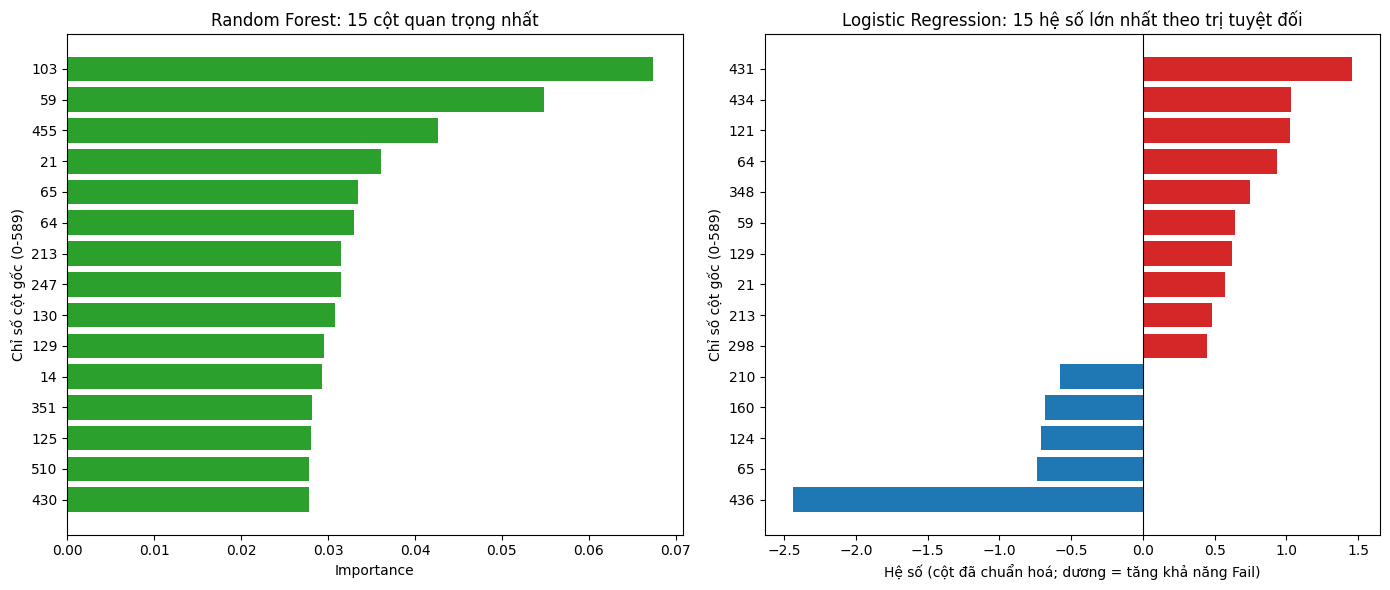

Số cột cùng nằm trong top 15 của RF và top 15 của LR: 6


In [27]:
top_rf = importance_table.sort_values("Importance (RF)", ascending=False).head(15).sort_values("Importance (RF)")
top_lr = importance_table.reindex(importance_table["Hệ số (LR)"].abs().sort_values(ascending=False).index).head(15)
top_lr = top_lr.sort_values("Hệ số (LR)")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].barh(top_rf["Cột gốc"].astype(str), top_rf["Importance (RF)"], color="tab:green")
axes[0].set_xlabel("Importance")
axes[0].set_ylabel("Chỉ số cột gốc (0-589)")
axes[0].set_title("Random Forest: 15 cột quan trọng nhất")

bar_colors = ["tab:red" if value > 0 else "tab:blue" for value in top_lr["Hệ số (LR)"]]
axes[1].barh(top_lr["Cột gốc"].astype(str), top_lr["Hệ số (LR)"], color=bar_colors)
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set_xlabel("Hệ số (cột đã chuẩn hoá; dương = tăng khả năng Fail)")
axes[1].set_ylabel("Chỉ số cột gốc (0-589)")
axes[1].set_title("Logistic Regression: 15 hệ số lớn nhất theo trị tuyệt đối")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_04_importance_coefficients.png", dpi=150)
plt.show()

overlap_top15 = len(set(top_rf["Cột gốc"]) & set(top_lr["Cột gốc"]))
print("Số cột cùng nằm trong top 15 của RF và top 15 của LR:", overlap_top15)

### Nhận xét

- **Phát hiện:** cột có importance cao nhất ở Random Forest là cột 103 (0,067), tiếp theo là các cột 59, 455, 21, 65 (importance 0,034–0,055); cột 103 cũng là cột có F-score cao nhất ở notebook 03. Hệ số Logistic Regression lớn nhất theo trị tuyệt đối trong cả 40 cột là cột 436 (−2,44), cột này không nằm trong top 15 của Random Forest; trong 15 cột đứng đầu của Random Forest, hệ số lớn nhất là cột 64 (+0,93), còn cột 103 có hệ số nhỏ (−0,09). Chỉ 6 cột cùng nằm trong top 15 của hai mô hình.
- **Ảnh hưởng:** hai mô hình xếp hạng cột khá khác nhau. Importance của Random Forest bị ảnh hưởng bởi các cột tương quan cao (importance bị chia nhỏ giữa các cột giống nhau), còn hệ số Logistic Regression ở không gian đã chuẩn hoá, dấu phụ thuộc mã nhãn 1 = Fail.
- **Kết luận:** đây **không phải quan hệ nhân quả** và không gán ý nghĩa vật lý cho cột. Diễn giải đúng cấu hình pipeline cuối (Random Forest, 40 cột gốc đã chọn); danh sách cột chỉ là gợi ý để kỹ sư có kiến thức miền kiểm tra thêm.

## 8. Kết luận về mức chấp nhận

*Nhãn: Nhóm bổ sung (slide 03: Accept / Improve / Redesign).*

Đối chiếu số đo với tiêu chí đặt ở mục 2. Verdict áp dụng cho **prototype**.

In [28]:
train_fail_rate = float(y_train.mean())
final_ap = final_metrics["average_precision"]
final_balanced_accuracy = final_metrics["balanced_accuracy"]

technical_ap_pass = final_ap > train_fail_rate
technical_ba_pass = final_balanced_accuracy > 0.5

ap_change_min = test_robustness["average_precision_chênh_so_với_sạch"].min()
ap_change_max = test_robustness["average_precision_chênh_so_với_sạch"].max()

verdict_rows = [
    {"Tiêu chí": "Kỹ thuật: Average Precision", "Mục tiêu đặt trước": f"> tỷ lệ Fail của train ({train_fail_rate:.4f})",
     "Kết quả đo": f"{final_ap:.4f}", "Kết luận": "Đạt" if technical_ap_pass else "Chưa đạt",
     "Nhận xét": "So với mốc ngây thơ; không có nghĩa là đủ tốt cho vận hành"},
    {"Tiêu chí": "Kỹ thuật: Balanced Accuracy", "Mục tiêu đặt trước": "> 0,5",
     "Kết quả đo": f"{final_balanced_accuracy:.4f}", "Kết luận": "Đạt" if technical_ba_pass else "Chưa đạt",
     "Nhận xét": f"BER = {final_metrics['ber']:.4f}"},
    {"Tiêu chí": "Vận hành: latency một quan sát", "Mục tiêu đặt trước": "Chưa đặt mục tiêu số",
     "Kết quả đo": f"{latency_single_ms:.2f} ms (median)", "Kết luận": "Chưa đủ dữ liệu",
     "Nhận xét": "Đo trên một máy phát triển; không có yêu cầu thời gian thực của nhà máy"},
    {"Tiêu chí": "Vận hành: tải cảnh báo", "Mục tiêu đặt trước": "Chưa đặt mục tiêu số",
     "Kết quả đo": f"{alarm_rate * 100:.1f}% ({tp + fp}/{n_test}); FPR {fp / (fp + tn):.3f}", "Kết luận": "Chưa đủ dữ liệu",
     "Nhận xét": "Không có năng lực kiểm tra của nhà máy; không tăng ngưỡng để ép đạt"},
    {"Tiêu chí": "Vận hành: robustness", "Mục tiêu đặt trước": "Chưa đặt mục tiêu số",
     "Kết quả đo": f"AP thay đổi từ {ap_change_min:+.4f} đến {ap_change_max:+.4f} so với test sạch (4 kịch bản giả lập)", "Kết luận": "Chưa đủ dữ liệu",
     "Nhận xét": "Biến đổi giả lập, không đại diện đầy đủ cho sensor drift thật (kiểm tra theo thời gian thuộc notebook 06)"},
    {"Tiêu chí": "Công nghiệp: Fail chặn được / lọt", "Mục tiêu đặt trước": "Chỉ báo cáo",
     "Kết quả đo": f"TP = {tp}/{n_test_fail}, FN = {fn}/{n_test_fail}, FP = {fp}/{n_test_pass}", "Kết luận": "Chưa đủ dữ liệu",
     "Nhận xét": "Chưa có chi phí, downtime hay ROI; luồng kỹ sư xác nhận đã mô tả ở mục 5"},
]
verdict_table = pd.DataFrame(verdict_rows)
with pd.option_context("display.max_colwidth", None):
    display(verdict_table)

,Tiêu chí,Mục tiêu đặt trước,Kết quả đo,Kết luận,Nhận xét
0,Kỹ thuật: Average Precision,> tỷ lệ Fail của train (0.0662),0.2102,Đạt,So với mốc ngây thơ; không có nghĩa là đủ tốt cho vận hành
1,Kỹ thuật: Balanced Accuracy,"> 0,5",0.6461,Đạt,BER = 0.3539
2,Vận hành: latency một quan sát,Chưa đặt mục tiêu số,27.84 ms (median),Chưa đủ dữ liệu,Đo trên một máy phát triển; không có yêu cầu thời gian thực của nhà máy
3,Vận hành: tải cảnh báo,Chưa đặt mục tiêu số,10.8% (34/314); FPR 0.089,Chưa đủ dữ liệu,Không có năng lực kiểm tra của nhà máy; không tăng ngưỡng để ép đạt
4,Vận hành: robustness,Chưa đặt mục tiêu số,AP thay đổi từ -0.0065 đến +0.0070 so với test sạch (4 kịch bản giả lập),Chưa đủ dữ liệu,"Biến đổi giả lập, không đại diện đầy đủ cho sensor drift thật (kiểm tra theo thời gian thuộc notebook 06)"
5,Công nghiệp: Fail chặn được / lọt,Chỉ báo cáo,"TP = 8/21, FN = 13/21, FP = 26/293",Chưa đủ dữ liệu,"Chưa có chi phí, downtime hay ROI; luồng kỹ sư xác nhận đã mô tả ở mục 5"


In [29]:
technical_pass = technical_ap_pass and technical_ba_pass
has_missing_evidence = (verdict_table["Kết luận"] == "Chưa đủ dữ liệu").any()

if not technical_pass:
    verdict = "Redesign"
elif has_missing_evidence:
    verdict = "Improve"
else:
    verdict = "Accept"

print("Verdict cho prototype:", verdict)
print("Lý do: tiêu chí kỹ thuật", "đạt" if technical_pass else "chưa đạt",
      "; còn tiêu chí vận hành/công nghiệp ở trạng thái 'chưa đủ dữ liệu'." if has_missing_evidence else ".")
print("Chưa đủ bằng chứng chấp nhận triển khai nhà máy.")

Verdict cho prototype: Improve
Lý do: tiêu chí kỹ thuật đạt ; còn tiêu chí vận hành/công nghiệp ở trạng thái 'chưa đủ dữ liệu'.
Chưa đủ bằng chứng chấp nhận triển khai nhà máy.


### Nhận xét

- **Phát hiện:** theo các tiêu chí đặt ở mục 2, **verdict cho prototype là Improve**. Tiêu chí kỹ thuật đạt (AP 0,210 > 0,066; Balanced Accuracy 0,646 > 0,5). Các tiêu chí vận hành và công nghiệp được đo và báo cáo nhưng chưa đặt mục tiêu số nên ở trạng thái "chưa đủ dữ liệu".
- **Ảnh hưởng:** có tín hiệu nhưng khiêm tốn (bắt 8/21 Fail, khoảng 108 cảnh báo trên 1.000 quan sát) và chưa có tiêu chí để biết mức đó có chấp nhận được trong nhà máy hay không. Không tăng ngưỡng hay đổi model để ép số đẹp hơn.
- **Giới hạn:** random split trong khi dữ liệu có thể đổi theo thời gian (notebook 01 thấy tỷ lệ Fail thay đổi theo tuần); chỉ 21 Fail trong test; không có tên sensor, định nghĩa Fail và chi phí; chưa xác nhận các phép đo đầu vào có sẵn trước thời điểm cần quyết định.
- **Chưa đủ bằng chứng chấp nhận triển khai nhà máy.**
- **Chuyển tiếp notebook 05:** nạp `model_final.joblib` và `decision_config.json`, không nhân đôi tiền xử lý.

## Kết luận

Notebook này đánh giá model cuối của notebook 03 (Random Forest, ngưỡng 0,14) một lần trên test 314 quan sát (21 Fail), không fit hay đổi ngưỡng. Ở mức model, mô hình phát hiện 8/21 Fail (Recall 0,381) với 26/293 Pass bị cảnh báo nhầm (FPR 0,089); AP = 0,210 và Balanced Accuracy = 0,646, vượt mốc ngây thơ (AP 0,066; 0,5) và sát AP trong CV (0,204 ± 0,070). Ở mức system, có khoảng 108 cảnh báo trên 1.000 quan sát, latency median khoảng 28–30 ms cho một quan sát (khoảng 7 ms với `n_jobs=1`), và nhiễu hay che thêm dữ liệu làm Recall giảm tối đa khoảng 0,06, tương đương 1–2 ca Fail. Ở mức industrial chỉ báo được số đếm (TP 8, FN 13, FP 26), chưa có chi phí hay ROI. Theo tiêu chí đặt trước, verdict là Improve: có tín hiệu nhưng chưa đủ bằng chứng chấp nhận triển khai nhà máy. Hạn chế: chỉ 21 Fail, random split, không có tên sensor hay chi phí. Notebook 05 sẽ nạp `model_final.joblib` và `decision_config.json`.

## Điểm cần ghi nhớ

- Test chỉ được dùng một lần để đánh giá: không fit, không tuning, không đổi ngưỡng, không chọn lại model theo điểm test.
- Tiêu chí chấp nhận được viết trước kết quả (đầu notebook, dạng markdown); không đặt mục tiêu số cho latency và tải cảnh báo vì không có yêu cầu của nhà máy.
- Với 21 Fail, mỗi ca đổi Recall 4,76 điểm phần trăm; báo số đếm (8/21, 26/293) cạnh tỷ lệ, không có khoảng tin cậy.
- Ngưỡng 0,14 chọn ở notebook 03 giữ nguyên; ở ngưỡng 0,5 Random Forest không gắn cờ quan sát nào.
- Cột gốc đã chọn đọc từ `decision_config.json`, không ánh xạ lại; importance và hệ số không phải quan hệ nhân quả.
- Verdict Improve không có nghĩa là sẵn sàng cho nhà máy; luôn cần kỹ sư xác nhận trước khi hành động.